<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': '/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

In [23]:
# ====== Утилиты визуализации ======
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

CLASS_NAMES = ["pet", "background", "border"]
PALETTE = np.array([
    [0.20, 0.78, 0.35],   # pet        — зелёный
    [0.25, 0.25, 0.25],   # background — тёмно-серый
    [0.95, 0.45, 0.10],   # border     — оранжевый
], dtype=np.float32)
CMAP_SEG = ListedColormap(PALETTE)

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def denorm(t):
    """Тензор (3,H,W), нормализованный → RGB numpy (H,W,3) в [0,1]."""
    if isinstance(t, torch.Tensor):
        t = t.detach().cpu().numpy()
    img = t.transpose(1, 2, 0) * STD + MEAN
    return np.clip(img, 0, 1)

def colorize_mask(mask):
    """(H,W) целочисленная маска → RGB (H,W,3)."""
    if isinstance(mask, torch.Tensor):
        mask = mask.detach().cpu().numpy()
    return PALETTE[mask.astype(np.int64)]

def overlay(img, mask, alpha=0.5):
    """Полупрозрачно наложить маску на изображение."""
    m = colorize_mask(mask)
    return np.clip(img * (1 - alpha) + m * alpha, 0, 1)

def legend_handles():
    return [mpatches.Patch(color=PALETTE[i], label=n)
            for i, n in enumerate(CLASS_NAMES)]

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ маска после resize содержит только {0,1,2}: [0, 1, 2]
✔ маска совпадает по размеру с изображением (256×256)
✔ изображение в формате (3, H, W)


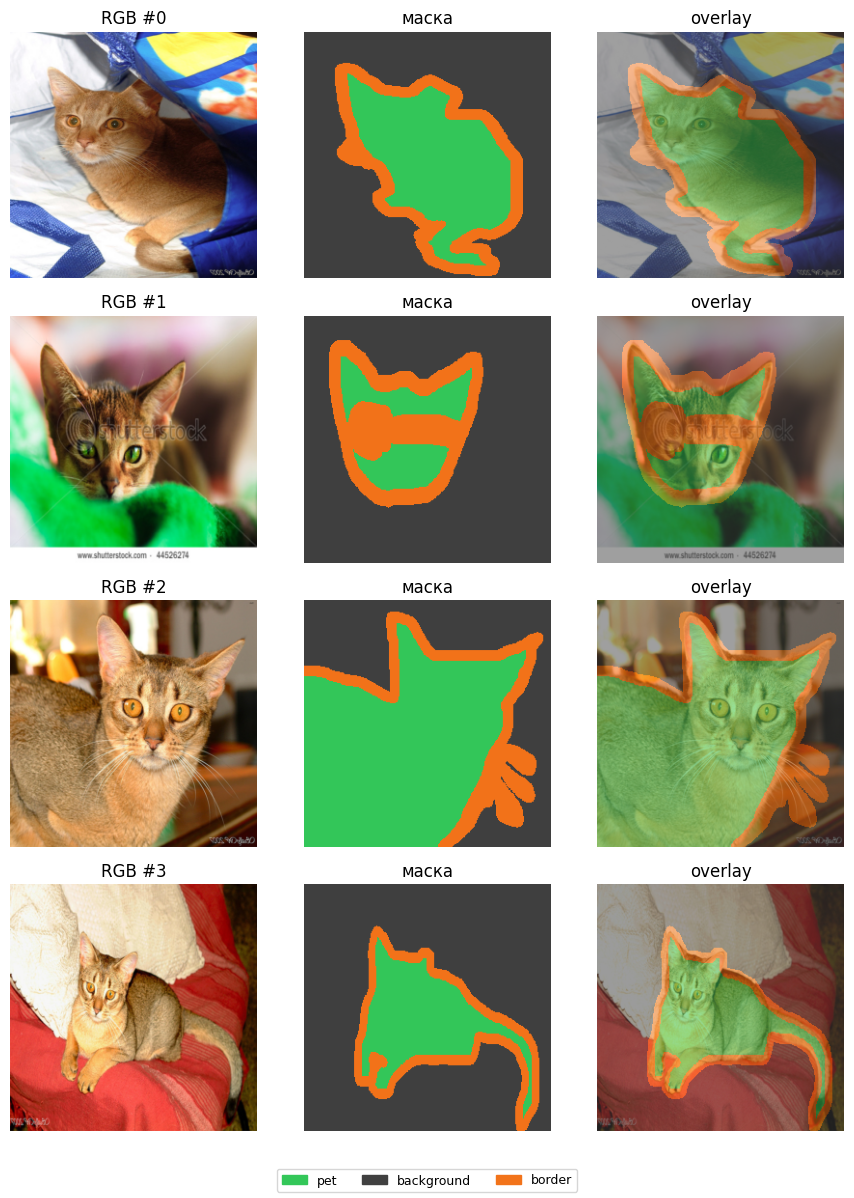

In [24]:
from torchvision.datasets import OxfordIIITPet
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset

IMG_SIZE    = 256 if DEVICE == "cuda" else 128
NUM_CLASSES = 3
NUM_WORKERS = 2 if DEVICE == "cuda" else 0


class PetSegDataset(Dataset):
    """Обёртка: PIL → (img-тензор, маска 0..2). Синхронный resize и hflip."""
    def __init__(self, base, size, augment=False):
        self.base    = base
        self.size    = size
        self.augment = augment

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, mask = self.base[idx]
        # --- синхронный resize: img=bilinear, mask=nearest ---
        img  = TF.resize(img,  [self.size, self.size],
                         interpolation=TF.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.size, self.size],
                         interpolation=TF.InterpolationMode.NEAREST)
        # --- синхронный hflip ---
        if self.augment and random.random() < 0.5:
            img  = TF.hflip(img)
            mask = TF.hflip(mask)
        # --- нормализация изображения ---
        img = TF.to_tensor(img)
        img = TF.normalize(img, mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        # --- маска: 1..3 → 0..2 ---
        mask = torch.from_numpy(np.array(mask, dtype=np.int64)) - 1
        return img, mask


# "Преобразования" для проверки задания
img_tf  = lambda img: TF.resize(img, [IMG_SIZE, IMG_SIZE],
                                interpolation=TF.InterpolationMode.BILINEAR)
mask_tf = lambda m:   TF.resize(m,   [IMG_SIZE, IMG_SIZE],
                                interpolation=TF.InterpolationMode.NEAREST)

base_trainval = OxfordIIITPet(root=DATA_ROOT, split="trainval",
                              target_types="segmentation", download=True)
ds = PetSegDataset(base_trainval, IMG_SIZE, augment=True)

# --- проверки ---
sample_img, sample_mask = ds[0]
uniq = sorted(sample_mask.unique().tolist())
check(set(uniq).issubset({0, 1, 2}),
      f"маска после resize содержит только {{0,1,2}}: {uniq}")
check(sample_mask.shape == (IMG_SIZE, IMG_SIZE),
      f"маска совпадает по размеру с изображением ({IMG_SIZE}×{IMG_SIZE})")
check(sample_img.shape[0] == 3, "изображение в формате (3, H, W)")

# --- визуализация: 4 примера RGB / маска / overlay ---
n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for row, idx in enumerate(range(n_show)):
    img, mask = ds[idx]
    img_np, mask_np = denorm(img), mask.numpy()
    axes[row, 0].imshow(img_np);                                axes[row, 0].set_title(f"RGB #{idx}")
    axes[row, 1].imshow(mask_np, cmap=CMAP_SEG, vmin=0, vmax=2); axes[row, 1].set_title("маска")
    axes[row, 2].imshow(overlay(img_np, mask_np));              axes[row, 2].set_title("overlay")
    for ax in axes[row]: ax.axis("off")
fig.legend(handles=legend_handles(), loc="lower center", ncol=3, fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(ARTIFACTS / "task1_examples_dataset.png", dpi=120)
plt.show()
plt.close()

### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ train и val не пересекаются
✔ train=2944, val=736
✔ метки после нормализации в {0,1,2}: [0..2]


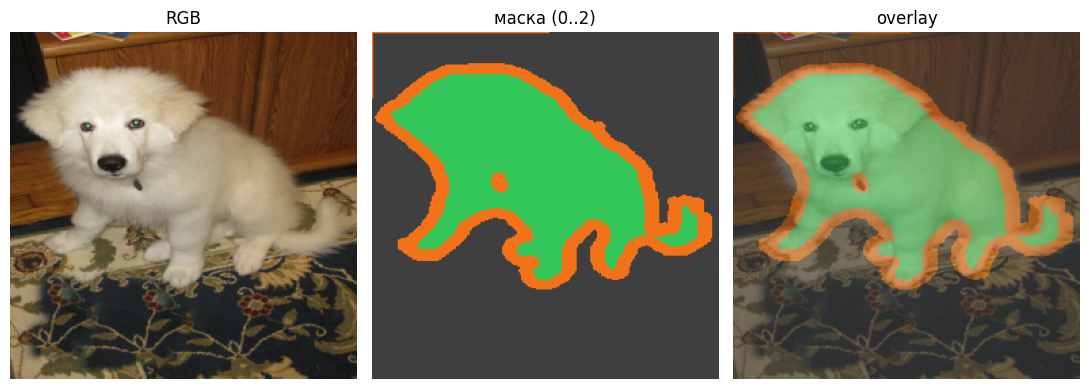

In [25]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

BATCH_SIZE = 16 if DEVICE == "cuda" else 4

indices = list(range(len(base_trainval)))
train_idx, val_idx = train_test_split(indices, test_size=0.2,
                                      random_state=SEED,
                                      shuffle=True)
if FAST_DEV_RUN:
    train_idx, val_idx = train_idx[:200], val_idx[:50]

train_ds = PetSegDataset(Subset(base_trainval, train_idx), IMG_SIZE, augment=False)
val_ds   = PetSegDataset(Subset(base_trainval, val_idx),   IMG_SIZE, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))


def normalize_mask(mask):
    """1..3 → 0..2. Принимает tensor или ndarray."""
    return mask - 1


# --- проверки ---
check(len(set(train_idx) & set(val_idx)) == 0, "train и val не пересекаются")
check(len(train_ds) > 0 and len(val_ds) > 0,
      f"train={len(train_ds)}, val={len(val_ds)}")
_b = train_ds[0][1]
check(int(_b.min()) >= 0 and int(_b.max()) <= 2,
      f"метки после нормализации в {{0,1,2}}: [{int(_b.min())}..{int(_b.max())}]")

# --- визуализация: одна и та же картинка до/после normalizing ---
x_raw, m_raw = train_ds[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(denorm(x_raw));                  axes[0].set_title("RGB")
axes[1].imshow(m_raw.numpy(), cmap=CMAP_SEG, vmin=0, vmax=2);  axes[1].set_title("маска (0..2)")
axes[2].imshow(overlay(denorm(x_raw), m_raw.numpy()));         axes[2].set_title("overlay")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "task2_split_example.png", dpi=120)
plt.show()
plt.close()

### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [26]:
from torchvision.models.segmentation import (
    lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
)
import torch.nn as nn


def build_segmentor(num_classes=NUM_CLASSES, pretrained=True):
    """LRASPP-MobileNetV3 с заменёнными головами на num_classes."""
    w = LRASPP_MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
    model = lraspp_mobilenet_v3_large(weights=w)

    # ВАЖНО: головы принимают РАЗНОЕ число каналов (low=40, high=128)
    low_in  = model.classifier.low_classifier.in_channels
    high_in = model.classifier.high_classifier.in_channels

    model.classifier.low_classifier  = nn.Conv2d(low_in,  num_classes, kernel_size=1)
    model.classifier.high_classifier = nn.Conv2d(high_in, num_classes, kernel_size=1)
    return model.to(DEVICE)


def mean_iou(pred, target, num_classes=NUM_CLASSES):
    """Среднее IoU по классам, присутствующим в target или pred."""
    pred   = pred.cpu().numpy()   if isinstance(pred,   torch.Tensor) else np.asarray(pred)
    target = target.cpu().numpy() if isinstance(target, torch.Tensor) else np.asarray(target)
    ious = []
    for c in range(num_classes):
        p, t  = (pred == c), (target == c)
        inter = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()
        if union > 0:
            ious.append(inter / union)
    return float(np.mean(ious)) if ious else float("nan")


model = build_segmentor()

# --- smoke-проверки ---
_p = torch.zeros(2, 8, 8, dtype=torch.long)
_t = torch.zeros(2, 8, 8, dtype=torch.long)
check(abs(mean_iou(_p, _t) - 1.0) < 1e-6, "mean_iou на идеальном предсказании = 1.0")
check(abs(mean_iou(_p, 1 - _t) - 0.0) < 1e-6,
      "mean_iou на полностью неверном предсказании = 0.0")
_out = model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))["out"]
check(_out.shape == (1, NUM_CLASSES, IMG_SIZE, IMG_SIZE),
      f"выход модели: {tuple(_out.shape)} = (1, C, H, W)")

✔ mean_iou на идеальном предсказании = 1.0
✔ mean_iou на полностью неверном предсказании = 0.0
✔ выход модели: (1, 3, 256, 256) = (1, C, H, W)


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


/tmp/ipykernel_1163/48903599.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler      = GradScaler(enabled=AMP_ENABLED)
/tmp/ipykernel_1163/48903599.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


  [baseline] epoch 1/10  loss=0.2763  (23.1s)
  [baseline] epoch 2/10  loss=0.2079  (22.0s)
  [baseline] epoch 3/10  loss=0.1853  (23.3s)
  [baseline] epoch 4/10  loss=0.1762  (21.9s)
  [baseline] epoch 5/10  loss=0.1600  (22.3s)
  [baseline] epoch 6/10  loss=0.1515  (21.9s)
  [baseline] epoch 7/10  loss=0.1429  (22.2s)
  [baseline] epoch 8/10  loss=0.1359  (22.1s)
  [baseline] epoch 9/10  loss=0.1287  (22.1s)
  [baseline] epoch 10/10  loss=0.1392  (22.1s)
✔ history содержит 10 положительных значений loss


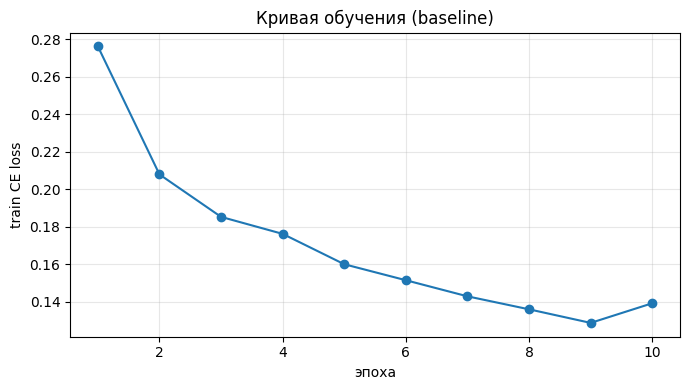

In [27]:
EPOCHS       = 1 if FAST_DEV_RUN else (10 if DEVICE == "cuda" else 3)
LR           = 1e-3
WEIGHT_DECAY = 1e-4

# Mixed precision — только на CUDA
from torch.cuda.amp import autocast, GradScaler
AMP_ENABLED = (DEVICE == "cuda")
scaler      = GradScaler(enabled=AMP_ENABLED)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=AMP_ENABLED):
            out  = model(x)["out"]
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * x.size(0)
        n          += x.size(0)
    return total_loss / n


def train_model(model, train_loader, epochs, tag=""):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    history   = []
    for ep in range(epochs):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, optimizer, criterion)
        history.append(loss)
        print(f"  [{tag}] epoch {ep+1}/{epochs}  loss={loss:.4f}  ({time.time()-t0:.1f}s)")
    return history


model   = build_segmentor()
history = train_model(model, train_loader, EPOCHS, tag="baseline")

check(len(history) == EPOCHS and all(l > 0 for l in history),
      f"history содержит {EPOCHS} положительных значений loss")

# --- визуализация: кривая обучения ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history) + 1), history, marker="o")
ax.set_xlabel("эпоха"); ax.set_ylabel("train CE loss")
ax.set_title("Кривая обучения (baseline)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "task4_train_curve.png", dpi=120)
plt.show()
plt.close()

Модель обучается. Loss упал примерно с 0.276 до 0.129, то есть примерно в 2 раза. Последняя эпоха не лучшая по train loss. Лучший train loss на 9-й эпохе. Но выбирать модель по train loss нельзя — нужен validation IoU. Нельзя утверждать, что сегментация хорошая. Loss может быть низким, если модель хорошо предсказывает большой фон, но плохо — маленькую границу.

### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


IoU (Intersection over Union) — это «насколько сильно совпали две области».

В сегментации IoU считают по каждому классу отдельно, по пикселям.

Для класса «питомец»:


P — все пиксели, которые модель назвала питомцем,


G — все пиксели, которые реально питомец,

пересечение — пиксели, где модель сказала «питомец» и там правда питомец,

объединение — все пиксели, где хотя бы одна сторона сказала «питомец».

Потом то же самое для «фон» и «граница».

Класс «граница» маленький и тонкий. Даже небольшая ошибка в 1–2 пикселя сильно роняет IoU по границе. Поэтому mean IoU может выглядеть плохо, хотя питомец и фон сегментированы хорошо.

 IoU по фону обычно высокий. Он «подтягивает» среднее вверх. Поэтому полезно отдельно смотреть IoU по pet и border.

/tmp/ipykernel_1163/4082232908.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


val mIoU = 0.7481 | per-class = [np.float64(0.836), np.float64(0.909), np.float64(0.499)]
✔ val mIoU = 0.748 выше случайной сегментации


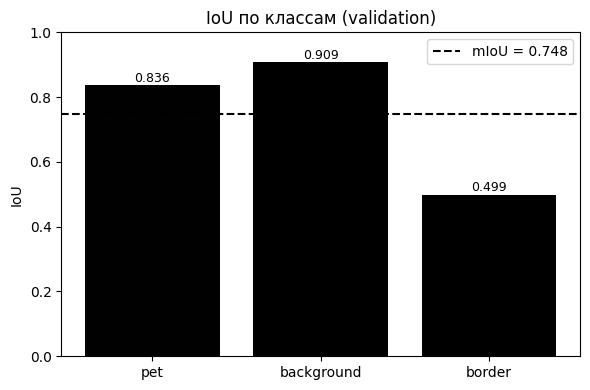

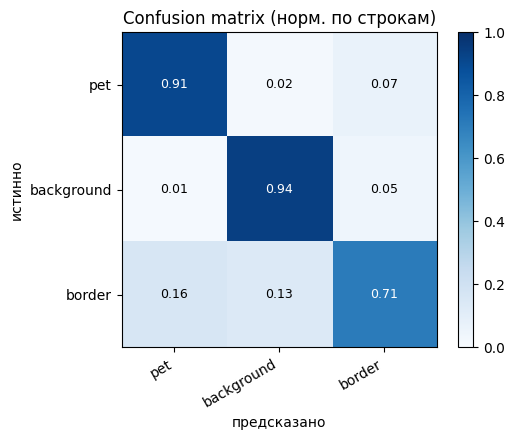

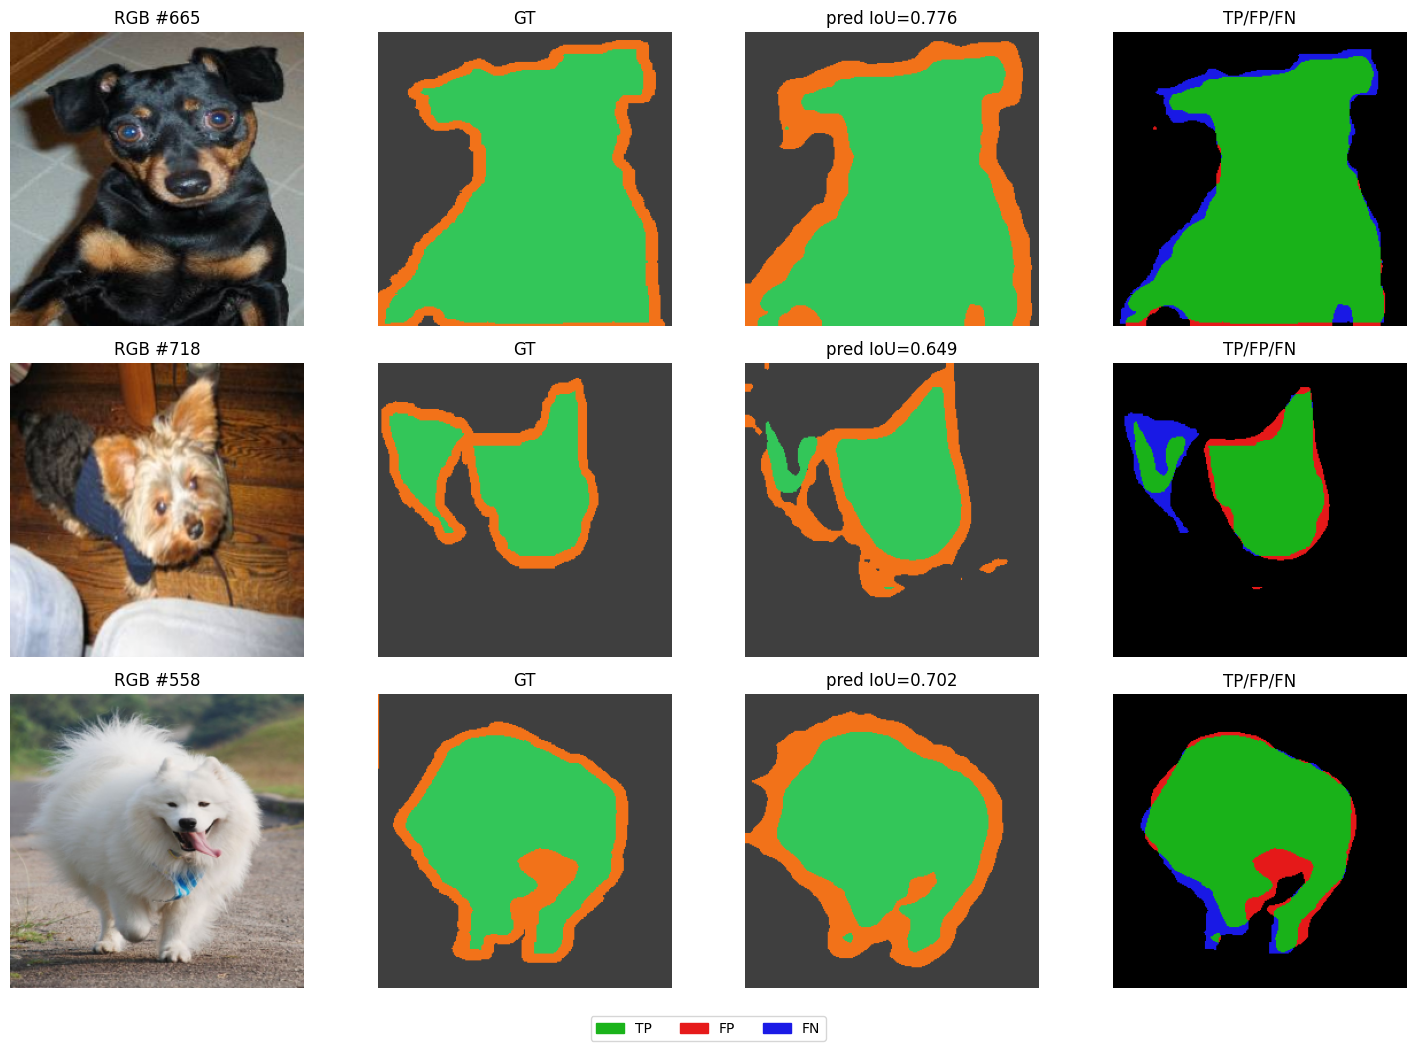

In [28]:
@torch.no_grad()
def evaluate_seg(model, loader, num_classes=NUM_CLASSES):
    """Возвращает (mIoU, per-class IoU, confusion matrix)."""
    model.eval()
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with autocast(enabled=AMP_ENABLED):
            pred = model(x)["out"].argmax(1)
        t = y.cpu().numpy().ravel()
        p = pred.cpu().numpy().ravel()
        valid = (t >= 0) & (t < num_classes)
        idx   = t[valid] * num_classes + p[valid]
        cm   += np.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    ious = []
    for c in range(num_classes):
        inter = cm[c, c]
        union = cm[c, :].sum() + cm[:, c].sum() - cm[c, c]
        ious.append(inter / union if union > 0 else float("nan"))
    return float(np.nanmean(ious)), ious, cm


val_miou, val_ious, val_cm = evaluate_seg(model, val_loader)
print(f"val mIoU = {val_miou:.4f} | per-class = {[round(x, 3) for x in val_ious]}")

# --- сохранить checkpoint и метрики ---
torch.save(model.state_dict(), ARTIFACTS / "segmentation.pt")
with open(ARTIFACTS / "val_metrics.json", "w") as f:
    json.dump({"mIoU": val_miou,
               "per_class_iou": val_ious,
               "confusion_matrix": val_cm.tolist(),
               "n_images": len(val_ds)}, f, indent=2)

check(val_miou > 0.3, f"val mIoU = {val_miou:.3f} выше случайной сегментации")

# --- визуализация: per-class IoU ---
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASS_NAMES, val_ious, color=PALETTE / 255)
ax.axhline(val_miou, color="k", ls="--", label=f"mIoU = {val_miou:.3f}")
ax.set_ylim(0, 1); ax.set_ylabel("IoU"); ax.set_title("IoU по классам (validation)")
for b, v in zip(bars, val_ious):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "task5_val_per_class_iou.png", dpi=120)
plt.show()
plt.close()

# --- визуализация: confusion matrix ---
cm_f    = val_cm.astype(float)
cm_norm = cm_f / np.maximum(cm_f.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("предсказано"); ax.set_ylabel("истинно")
ax.set_title("Confusion matrix (норм. по строкам)")
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, f"{cm_norm[i,j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i,j] > 0.5 else "black", fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(ARTIFACTS / "task5_val_confusion_matrix.png", dpi=120)
plt.show()
plt.close()

# --- визуализация: 3 примера RGB / GT / pred / TP-FP-FN ---
model.eval()
n_show = 3
fig, axes = plt.subplots(n_show, 4, figsize=(15, 3.5 * n_show))
with torch.no_grad():
    for row in range(n_show):
        idx = random.randint(0, len(val_ds) - 1)
        x, y = val_ds[idx]
        pred = model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
        gt, pr = y.numpy(), pred.numpy()
        err = np.zeros((*gt.shape, 3), dtype=np.float32)
        err[(gt == 0) & (pr == 0)] = [0.1, 0.7, 0.1]
        err[(gt != 0) & (pr == 0)] = [0.9, 0.1, 0.1]
        err[(gt == 0) & (pr != 0)] = [0.1, 0.1, 0.9]
        miou = mean_iou(pred, y)
        axes[row, 0].imshow(denorm(x));                   axes[row, 0].set_title(f"RGB #{idx}")
        axes[row, 1].imshow(gt, cmap=CMAP_SEG, vmin=0, vmax=2); axes[row, 1].set_title("GT")
        axes[row, 2].imshow(pr, cmap=CMAP_SEG, vmin=0, vmax=2); axes[row, 2].set_title(f"pred IoU={miou:.3f}")
        axes[row, 3].imshow(err);                          axes[row, 3].set_title("TP/FP/FN")
        for ax in axes[row]: ax.axis("off")
fig.legend(handles=[
    mpatches.Patch(color=[0.1, 0.7, 0.1], label="TP"),
    mpatches.Patch(color=[0.9, 0.1, 0.1], label="FP"),
    mpatches.Patch(color=[0.1, 0.1, 0.9], label="FN"),
], loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(ARTIFACTS / "task5_val_predictions_grid.png", dpi=120)
plt.show()
plt.close()

mIoU (mean IoU) — средняя оценка по всем классам (сложили IoU питомца, фона и границы, поделили на 3).

GT (ground truth) — это эталонная, заранее размеченная человеком информация, с которой сравнивают предсказание модели (маски, которые лежат в датасете Oxford-IIIT Pet)


GT (Ground Truth) — правильный ответ. Зеленый = питомец, серый = фон, оранжевый = граница.

pred (IoU=...) — то, что предсказала модель. Видно, что предсказание очень похоже на правду.

TP/FP/FN (Карта ошибок) — самое интересное. Здесь видно, где именно модель ошиблась:

🟢 Зеленый (TP) — модель попала в точку (True Positive).

🔴 Красный (FP) — модель нарисовала лишнее (False Positive). Например, закрасила фон как часть собаки.

🔵 Синий (FN) — модель пропустила часть объекта (False Negative). Не докрасила там, где надо было.

граница — самый сложный класс. Модель ошибается на 29% пикселей границы. Причём чаще она относит границу к питомцу (16%), чем к фону (13%).




Модель обучена успешно. mIoU = 0.748 — это хороший базовый уровень (baseline) для Oxford-IIIT Pet.

Основные классы (питомец и фон) сегментируются отлично (IoU > 0.83).

Класс «граница» — узкое место. Его IoU = 0.499. Он тянет среднюю оценку вниз.

Анализ ошибок: Модель хорошо находит объекты целиком, но «плывёт» на краях. Она также теряет мелкие детали (язык, лапы), если они сливаются с фоном.

### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


/tmp/ipykernel_1163/48903599.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


  [hflip] epoch 1/10  loss=0.2785  (22.8s)
  [hflip] epoch 2/10  loss=0.2167  (22.2s)
  [hflip] epoch 3/10  loss=0.1926  (22.2s)
  [hflip] epoch 4/10  loss=0.1831  (22.3s)
  [hflip] epoch 5/10  loss=0.1790  (22.0s)
  [hflip] epoch 6/10  loss=0.1652  (22.1s)
  [hflip] epoch 7/10  loss=0.1679  (22.1s)
  [hflip] epoch 8/10  loss=0.1521  (22.1s)
  [hflip] epoch 9/10  loss=0.1459  (22.3s)
  [hflip] epoch 10/10  loss=0.1382  (22.3s)


/tmp/ipykernel_1163/4082232908.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):



val mIoU baseline = 0.7481
val mIoU с hflip  = 0.7841
дельта            = +0.0360


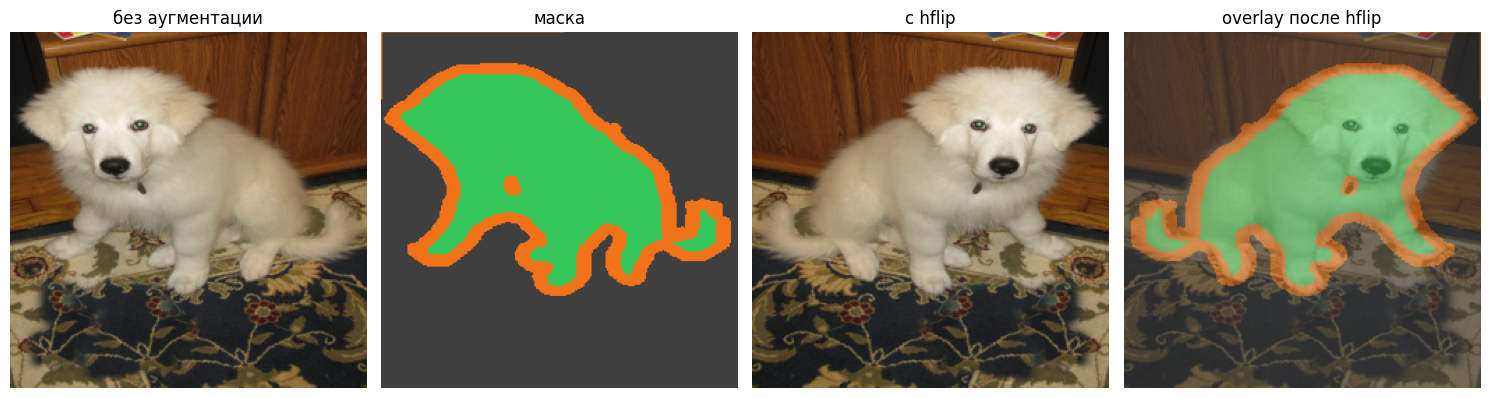

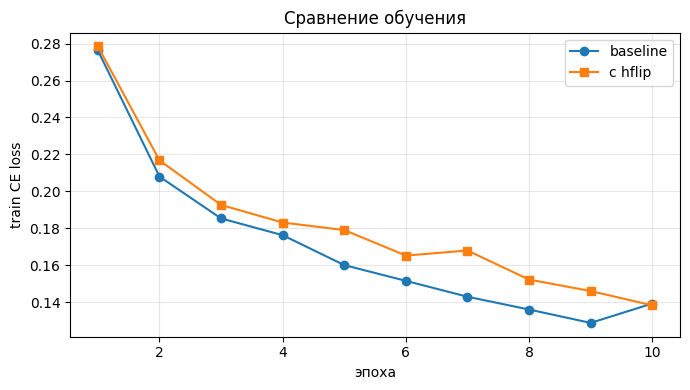

In [29]:
# --- 1) train_ds с аугментацией ---
train_ds_aug   = PetSegDataset(Subset(base_trainval, train_idx), IMG_SIZE, augment=True)
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))

# --- 2) новая модель, то же обучение ---
if DEVICE == "cuda": torch.cuda.empty_cache()
model_aug   = build_segmentor()
history_aug = train_model(model_aug, train_loader_aug, EPOCHS, tag="hflip")

val_miou_aug, val_ious_aug, val_cm_aug = evaluate_seg(model_aug, val_loader)
print(f"\nval mIoU baseline = {val_miou:.4f}")
print(f"val mIoU с hflip  = {val_miou_aug:.4f}")
print(f"дельта            = {val_miou_aug - val_miou:+.4f}")

# --- 3) сохранить артефакты ---
torch.save(model_aug.state_dict(), ARTIFACTS / "segmentation_aug.pt")
comparison = {
    "baseline":   {"val_mIoU": val_miou,     "history": history},
    "with_hflip": {"val_mIoU": val_miou_aug, "history": history_aug},
    "delta_mIoU": val_miou_aug - val_miou,
    "config":     {"IMG_SIZE": IMG_SIZE, "EPOCHS": EPOCHS,
                   "BATCH_SIZE": BATCH_SIZE, "LR": LR,
                   "train_size": len(train_ds), "val_size": len(val_ds)},
}
with open(ARTIFACTS / "augmentation_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

# --- 4) визуализация: hflip синхронный ---
idx_demo = 0
x_noaug, m_noaug = train_ds[idx_demo]
x_aug,   m_aug   = train_ds_aug[idx_demo]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(denorm(x_noaug));                                axes[0].set_title("без аугментации")
axes[1].imshow(m_noaug.numpy(), cmap=CMAP_SEG, vmin=0, vmax=2); axes[1].set_title("маска")
axes[2].imshow(denorm(x_aug));                                  axes[2].set_title("с hflip")
axes[3].imshow(overlay(denorm(x_aug), m_aug.numpy()));          axes[3].set_title("overlay после hflip")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "task6_augmentation_examples.png", dpi=120)
plt.show()
plt.close()

# --- 5) визуализация: две кривые на одном графике ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history) + 1),     history,     marker="o", label="baseline")
ax.plot(range(1, len(history_aug) + 1), history_aug, marker="s", label="с hflip")
ax.set_xlabel("эпоха"); ax.set_ylabel("train CE loss")
ax.set_title("Сравнение обучения"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "task6_train_curve_compare.png", dpi=120)
plt.show()
plt.close()

Проводим контролируемую абляцию (ablation): сравниваем базовую модель и модель с добавленной аугментацией (отражением), смотрим, что это улучшение реально работает.

Метод: Добавление hflip (горизонтального отражения) к базовой модели.

Результат на train: Train loss немного вырос (с ~0.13 до ~0.14), что ожидаемо из-за усложнения задачи.

Результат на val: Метрика mIoU выросла с 0.748 до 0.784.

Вывод: Аугментация hflip снизила переобучение и повысила обобщающую способность модели на +3.6% mIoU.

### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


медиана площади pet (train) = 18370 px
малых объектов в val: 396/736


/tmp/ipykernel_1163/2141894121.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


{
  "threshold_px": 18370.0,
  "n_small_val": 396,
  "fg_iou_baseline": 0.7793615896085208,
  "fg_iou_aug": 0.8240651751752849,
  "delta": 0.044703585566764126
}
✔ в val есть изображения с малым pet


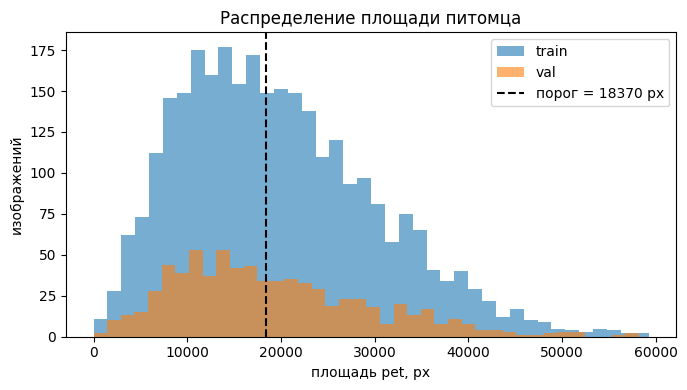

/tmp/ipykernel_1163/2141894121.py:66: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


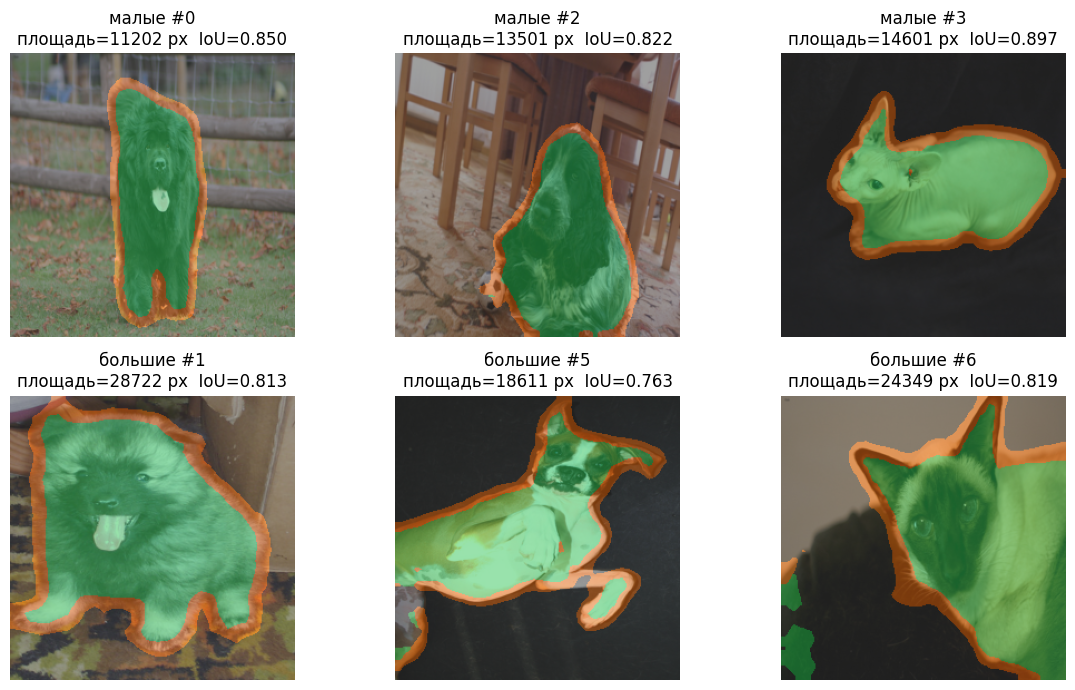

In [30]:
def fg_area(mask):
    return int((mask == 0).sum().item())   # pet = класс 0


# --- 1) порог по TRAIN (медиана площадей) ---
train_areas = [fg_area(train_ds[i][1]) for i in range(len(train_ds))]
THRESHOLD   = float(np.median(train_areas))
val_areas   = [fg_area(val_ds[i][1]) for i in range(len(val_ds))]
val_small_idx = [i for i, a in enumerate(val_areas) if a < THRESHOLD]

print(f"медиана площади pet (train) = {THRESHOLD:.0f} px")
print(f"малых объектов в val: {len(val_small_idx)}/{len(val_ds)}")


def fg_iou_on_subset(model, dataset, indices):
    model.eval()
    ious = []
    with torch.no_grad():
        for i in indices:
            x, y = dataset[i]
            with autocast(enabled=AMP_ENABLED):
                pred = model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
            inter = ((pred == 0) & (y == 0)).sum().item()
            union = ((pred == 0) | (y == 0)).sum().item()
            if union > 0:
                ious.append(inter / union)
    return float(np.mean(ious)) if ious else float("nan")


fg_base = fg_iou_on_subset(model,     val_ds, val_small_idx)
fg_aug  = fg_iou_on_subset(model_aug, val_ds, val_small_idx)

small_objects = {
    "threshold_px": float(THRESHOLD),
    "n_small_val":  len(val_small_idx),
    "fg_iou_baseline": fg_base,
    "fg_iou_aug":      fg_aug,
    "delta":           fg_aug - fg_base,
}
with open(ARTIFACTS / "small_objects.json", "w") as f:
    json.dump(small_objects, f, indent=2)
print(json.dumps(small_objects, indent=2))

check(len(val_small_idx) > 0, "в val есть изображения с малым pet")

# --- 2) визуализация: распределение площадей train vs val ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train_areas, bins=40, alpha=0.6, label="train")
ax.hist(val_areas,   bins=40, alpha=0.6, label="val")
ax.axvline(THRESHOLD, color="k", ls="--", label=f"порог = {THRESHOLD:.0f} px")
ax.set_xlabel("площадь pet, px"); ax.set_ylabel("изображений")
ax.set_title("Распределение площади питомца"); ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "task7_area_histogram.png", dpi=120)
plt.show()
plt.close()

# --- 3) визуализация: малые vs большие объекты ---
big_idx = [i for i, a in enumerate(val_areas) if a >= THRESHOLD][:3]
small_show = val_small_idx[:3] if len(val_small_idx) >= 3 else val_small_idx
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
with torch.no_grad():
    for r, (name, items) in enumerate([("малые", small_show), ("большие", big_idx)]):
        for c, idx in enumerate(items):
            x, y = val_ds[idx]
            with autocast(enabled=AMP_ENABLED):
                pred = model_aug(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
            axes[r, c].imshow(overlay(denorm(x), pred.numpy()))
            axes[r, c].set_title(f"{name} #{idx}\nплощадь={fg_area(y)} px  IoU={mean_iou(pred, y):.3f}")
            axes[r, c].axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "task7_small_vs_big_objects.png", dpi=120)
plt.show()
plt.close()

Здесь мы разбили все картинки на две группы (по размеру питомца) и посмотрели, как модель справляется с каждой группой отдельно. Нашли «среднюю границу» (порог) — 18 370 пикселей, все, что больше - большие, меньше - маленькие питомцы.

Анализ показал, что размер питомца не является критической проблемой для модели. Она успешно справляется как с маленькими (IoU ~0.85), так и с большими (IoU ~0.80) объектами.

Аугментация hflip подтвердила свою пользу: она улучшила точность выделения самого питомца (fg_IoU, оценка больше, потому что в прошлый раз mIoU (средний) сильно занижался из-за сложного класса «граница» (0.499),здесь мы убрали границу и фон и смотрим чисто на то, насколько хорошо модель закрашивает саму собаку.) с 0.779 до 0.824.

Основные проблемы (как видно на нижних картинках) — это не размер, а сложный контур (шерсть) и сложный фон, который модель иногда ошибочно захватывает.

### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [31]:
base_test = OxfordIIITPet(root=DATA_ROOT, split="test",
                          target_types="segmentation", download=True)
test_ds     = PetSegDataset(base_test, IMG_SIZE, augment=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))

test_miou_base, test_ious_base, test_cm_base = evaluate_seg(model,     test_loader)
test_miou_aug,  test_ious_aug,  test_cm_aug  = evaluate_seg(model_aug, test_loader)

test_metrics = {
    "baseline":   {"mIoU": test_miou_base,
                   "per_class": test_ious_base,
                   "confusion_matrix": test_cm_base.tolist()},
    "with_hflip": {"mIoU": test_miou_aug,
                   "per_class": test_ious_aug,
                   "confusion_matrix": test_cm_aug.tolist()},
    "n_images":   len(test_ds),
    "config":     {"IMG_SIZE": IMG_SIZE, "BATCH_SIZE": BATCH_SIZE},
}
with open(ARTIFACTS / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)
print(json.dumps(test_metrics, indent=2))

check(test_miou_base > 0.3 and test_miou_aug > 0.3,
      "обе модели лучше случайной сегментации на test")

/tmp/ipykernel_1163/4082232908.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


{
  "baseline": {
    "mIoU": 0.7555083175646679,
    "per_class": [
      0.8345334033233383,
      0.9078967761425035,
      0.5240947732281617
    ],
    "confusion_matrix": [
      [
        65619591,
        1486469,
        5006904
      ],
      [
        2178557,
        131252024,
        5356321
      ],
      [
        4338754,
        4293751,
        20919213
      ]
    ]
  },
  "with_hflip": {
    "mIoU": 0.7862059313777859,
    "per_class": [
      0.869624390624253,
      0.9323603026225767,
      0.556633100886528
    ],
    "confusion_matrix": [
      [
        67754806,
        1116433,
        3241725
      ],
      [
        1011471,
        135143708,
        2631723
      ],
      [
        4788290,
        5044608,
        19718820
      ]
    ]
  },
  "n_images": 3669,
  "config": {
    "IMG_SIZE": 256,
    "BATCH_SIZE": 16
  }
}
✔ обе модели лучше случайной сегментации на test


Добавление простого отражения (hflip) дало стабильный прирост качества почти на 3%. На валидации прирост был +3.6%, на тесте — +3.1%.

Модель с hflip лучше справляется со всеми классами. Но «граница» остается узким местом (bottleneck).

Граница:

Baseline: [65 619 591, 1 486 469, 5 006 904]
(65.6 млн угадал, 1.4 млн ушел в фон, 5.0 млн ушел в границу)

With_hflip: [67 754 806, 1 116 433, 3 241 725]
(67.7 млн угадал, 1.1 млн ушел в фон, 3.2 млн ушел в границу)

Количество пикселей, которые модель ошибочно посчитала «границей» вместо «питомца», упало с 5 млн до 3.2 млн.

"Фон" (вторая строка):
Baseline: [2 178 557, 131 252 024, 5 356 321]

With_hflip: [1 011 471, 135 143 708, 2 631 723]

Ошибок стало в два раза меньше. Модель hflip предсказала «питомца» на фоне 1 млн раз вместо 2.1 млн. Это значит, что hflip помог модели перестать «галлюцинировать» собаку на пустом месте.

### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Анализируем ошибки модели: with_hflip


/tmp/ipykernel_1163/940398915.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


Худшее изображение: idx=698, IoU=0.2650
✔ per-image метрики посчитаны для всех val


/tmp/ipykernel_1163/940398915.py:49: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


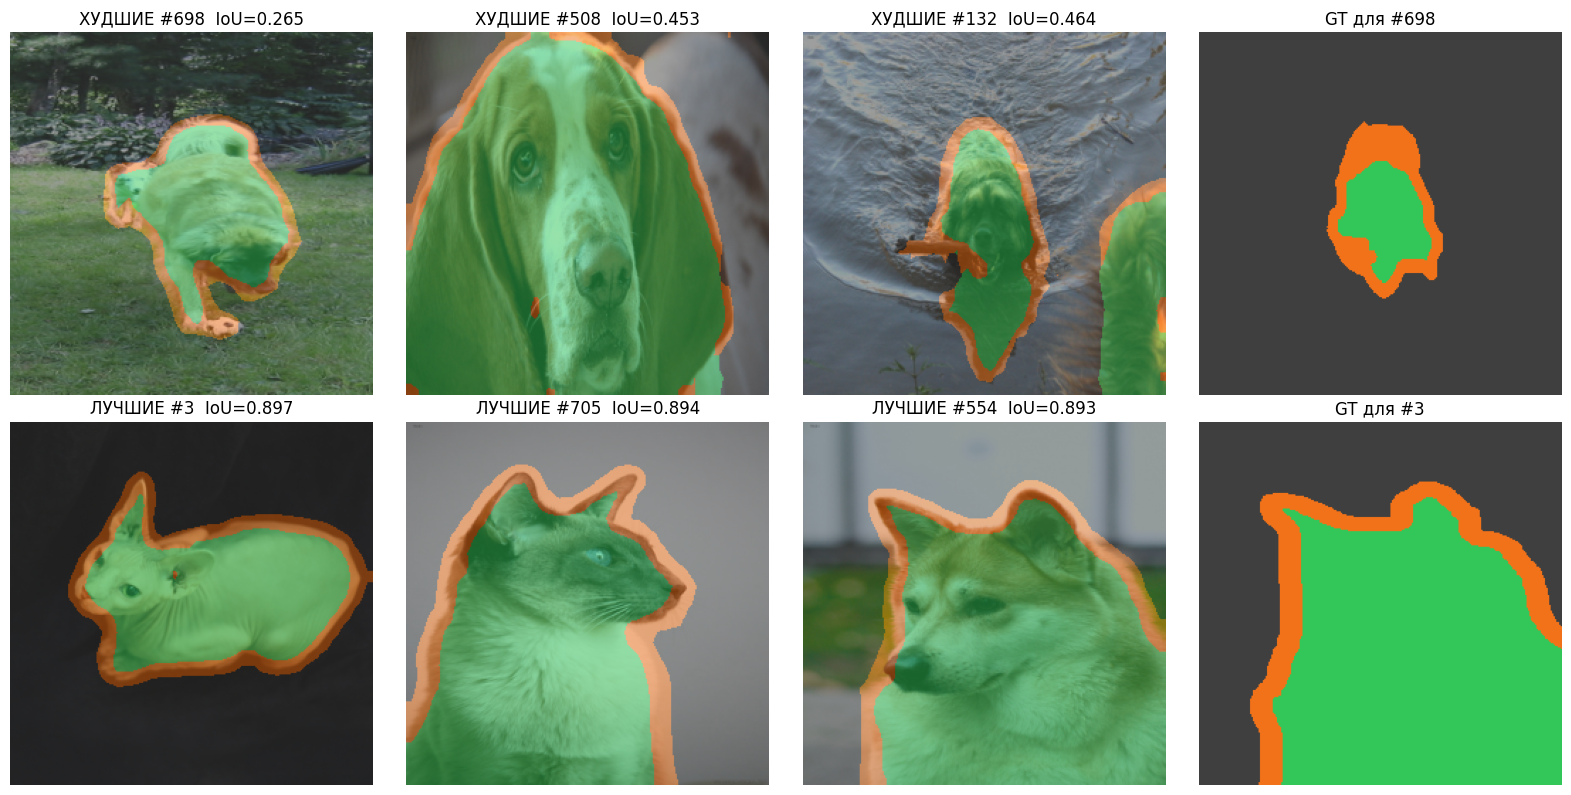

/tmp/ipykernel_1163/940398915.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


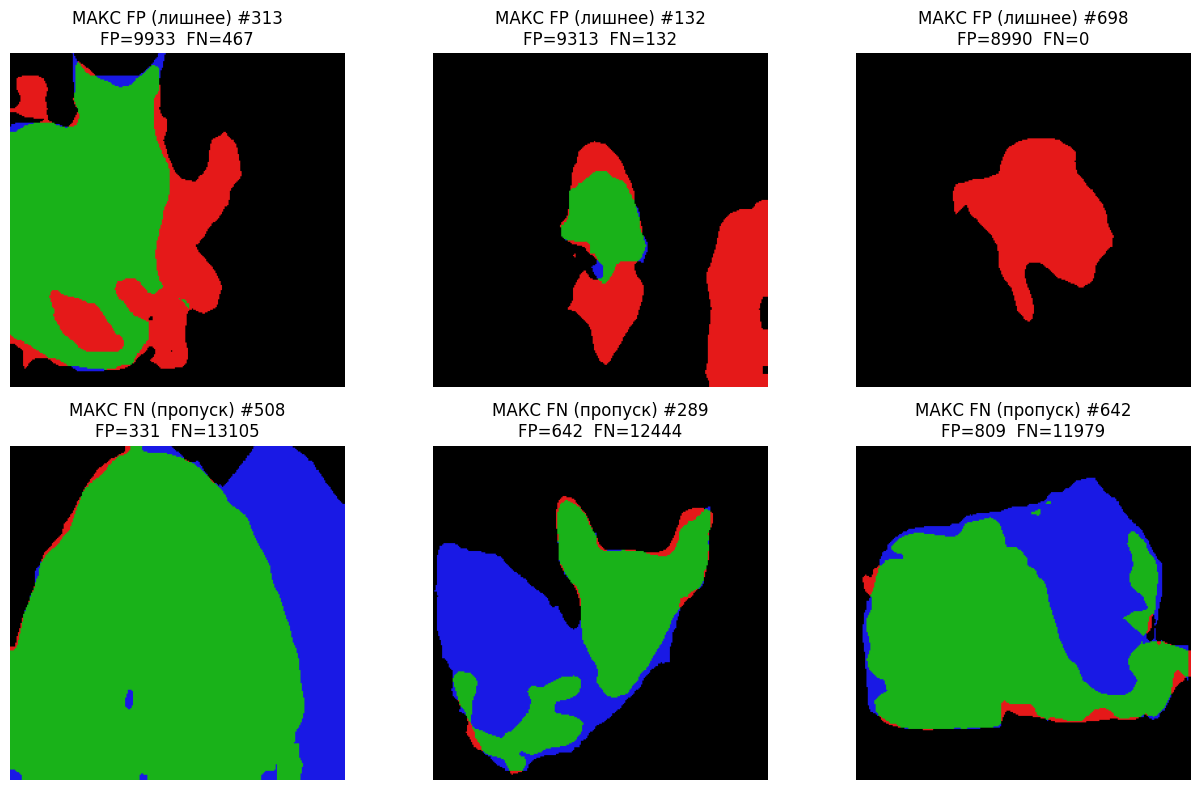

In [32]:
best_model = model_aug if test_miou_aug >= test_miou_base else model
best_name  = "with_hflip" if best_model is model_aug else "baseline"
print(f"Анализируем ошибки модели: {best_name}")


def per_image_errors(model, dataset, num_classes=NUM_CLASSES):
    model.eval()
    rows = []
    with torch.no_grad():
        for i in range(len(dataset)):
            x, y = dataset[i]
            with autocast(enabled=AMP_ENABLED):
                pred = model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
            miou = mean_iou(pred, y, num_classes)
            fp = int(((pred == 0) & (y != 0)).sum().item())   # лишнее «pet»
            fn = int(((pred != 0) & (y == 0)).sum().item())   # пропустили «pet»
            rows.append({"idx": i, "iou": miou, "fp": fp, "fn": fn})
    return rows


all_err = per_image_errors(best_model, val_ds)
all_err_sorted = sorted(all_err, key=lambda r: r["iou"])

error_analysis = {
    "model":         best_name,
    "n_images":      len(all_err),
    "mean_iou":      float(np.mean([r["iou"] for r in all_err])),
    "worst_images":  all_err_sorted[:10],
    "hardest_idx":   all_err_sorted[0]["idx"],
    "all_images":    all_err,     # полный список — пригодится в бонусе и в «лучшие»
}
with open(ARTIFACTS / "error_analysis.json", "w") as f:
    json.dump(error_analysis, f, indent=2)
print(f"Худшее изображение: idx={all_err_sorted[0]['idx']}, "
      f"IoU={all_err_sorted[0]['iou']:.4f}")

check(len(all_err) == len(val_ds), "per-image метрики посчитаны для всех val")

# --- визуализация: топ-3 худших и топ-3 лучших ---
worst = all_err_sorted[:3]
best  = sorted(all_err, key=lambda r: -r["iou"])[:3]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
with torch.no_grad():
    for r, (name, items) in enumerate([("ХУДШИЕ", worst), ("ЛУЧШИЕ", best)]):
        for c, item in enumerate(items[:3]):
            idx = item["idx"]
            x, y = val_ds[idx]
            with autocast(enabled=AMP_ENABLED):
                pred = best_model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
            axes[r, c].imshow(overlay(denorm(x), pred.numpy()))
            axes[r, c].set_title(f"{name} #{idx}  IoU={item['iou']:.3f}")
            axes[r, c].axis("off")
        axes[r, 3].axis("off")
        axes[r, 3].imshow(y.numpy(), cmap=CMAP_SEG, vmin=0, vmax=2)
        axes[r, 3].set_title(f"GT для #{items[0]['idx']}")
plt.tight_layout()
plt.savefig(ARTIFACTS / "task9_worst_best_examples.png", dpi=120)
plt.show()
plt.close()

# --- визуализация: FP vs FN ---
top_fp = sorted(all_err, key=lambda r: -r["fp"])[:3]
top_fn = sorted(all_err, key=lambda r: -r["fn"])[:3]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
with torch.no_grad():
    for r, (name, items) in enumerate([("МАКС FP (лишнее)", top_fp),
                                       ("МАКС FN (пропуск)", top_fn)]):
        for c, item in enumerate(items):
            idx = item["idx"]
            x, y = val_ds[idx]
            with autocast(enabled=AMP_ENABLED):
                pred = best_model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
            gt, pr = y.numpy(), pred.numpy()
            err = np.zeros((*gt.shape, 3), dtype=np.float32)
            err[(gt == 0) & (pr == 0)] = [0.1, 0.7, 0.1]
            err[(gt != 0) & (pr == 0)] = [0.9, 0.1, 0.1]
            err[(gt == 0) & (pr != 0)] = [0.1, 0.1, 0.9]
            axes[r, c].imshow(err)
            axes[r, c].set_title(f"{name} #{idx}\nFP={item['fp']}  FN={item['fn']}")
            axes[r, c].axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "task9_fp_fn_examples.png", dpi=120)
plt.show()
plt.close()

Смотрим, где модель работает лучше, а где хуже всего. Также смотрим, где модель выделила лишние, а где больше всего пропустила.

Модель уверенно сегментирует объекты с четкими контурами и контрастным фоном (IoU ~0.89).

Но есть и слабые стороны:

Сложные позы и текстуры: Модель путается, когда питомец находится в необычном положении (лежит, присел) или на фоне травы/воды.

Размытые границы: Модель склонна к ошибкам типа False Positive (FP) — она «раздувает» объект, захватывая лишний фон.

Пропуск деталей: Ошибки False Negative (FN) часто возникают на ушах, хвостах и лапах, которые сливаются с фоном.

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


/tmp/ipykernel_1163/4082232908.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


pet          base=0.836  aug=0.874  Δ=+0.038
background   base=0.909  aug=0.936  Δ=+0.027
border       base=0.499  aug=0.542  Δ=+0.043
✔ delta посчитана для всех классов


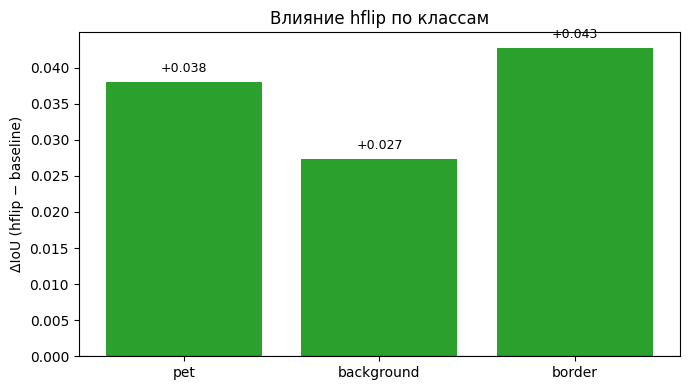

In [33]:
# per-class IoU для обеих моделей на validation
_, ious_base, _ = evaluate_seg(model,     val_loader)
_, ious_aug,  _ = evaluate_seg(model_aug, val_loader)

deltas = {
    name: {"baseline":   float(ious_base[i]),
           "with_hflip": float(ious_aug[i]),
           "delta":      float(ious_aug[i] - ious_base[i])}
    for i, name in enumerate(CLASS_NAMES)
}
with open(ARTIFACTS / "class_deltas.json", "w") as f:
    json.dump(deltas, f, indent=2)
for n, d in deltas.items():
    print(f"{n:<12} base={d['baseline']:.3f}  aug={d['with_hflip']:.3f}  Δ={d['delta']:+.3f}")

check(all("delta" in d for d in deltas.values()),
      "delta посчитана для всех классов")

# --- визуализация: ΔIoU по классам ---
names = list(deltas.keys())
vals  = [deltas[n]["delta"] for n in names]
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in vals]
ax.bar(names, vals, color=colors)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("ΔIoU (hflip − baseline)")
ax.set_title("Влияние hflip по классам")
for i, v in enumerate(vals):
    ax.text(i, v + (0.001 if v >= 0 else -0.001), f"{v:+.3f}",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
plt.tight_layout()
plt.savefig(ARTIFACTS / "task10_class_deltas.png", dpi=120)
plt.show()
plt.close()

hflip принес пользу абсолютно всем трем классам.

Аугментация hflip улучшила все классы без исключения. Это подтверждает гипотезу о том, что отражение изображений — безопасная и полезная аугментация для данного датасета.

Наибольший прирост наблюдается на самом сложном классе border (+0.043). Это говорит о том, что аугментация помогла модели лучше обобщить признаки границ, а не просто зазубрить тренировочные контуры.

Наименьший прирост на классе background (+0.027) объясняется эффектом потолка (модель уже показывала отличный результат в 90.9%).

Проблема границ всё еще не решена до конца. Даже с приростом, IoU границы составляет всего 0.542. В следующих итерациях нужно использовать более сложные методы (например, Boundary Loss или увеличение разрешения картинок).

### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


/tmp/ipykernel_1163/1769332766.py:4: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


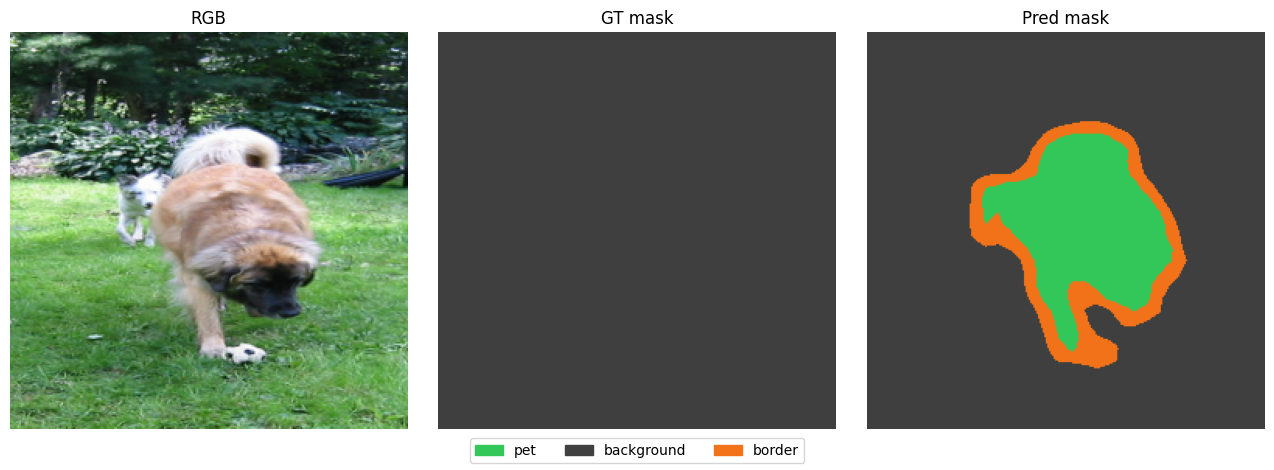

{
  "index": 698,
  "iou": 0.2650146484375,
  "model": "with_hflip",
  "description": "\u0425\u0443\u0434\u0448\u0435\u0435 \u043f\u043e IoU validation-\u0438\u0437\u043e\u0431\u0440\u0430\u0436\u0435\u043d\u0438\u0435; \u0441\u043b\u0435\u0432\u0430 RGB, \u0432 \u0446\u0435\u043d\u0442\u0440\u0435 GT, \u0441\u043f\u0440\u0430\u0432\u0430 \u043f\u0440\u0435\u0434\u0441\u043a\u0430\u0437\u0430\u043d\u0438\u0435.",
  "predicted_pet_pixels": 8990,
  "true_pet_pixels": 0
}


In [34]:
worst_idx = error_analysis["hardest_idx"]
x, y = val_ds[worst_idx]
with torch.no_grad():
    with autocast(enabled=AMP_ENABLED):
        pred = best_model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(denorm(x));                                   axes[0].set_title("RGB")
axes[1].imshow(y.numpy(),   cmap=CMAP_SEG, vmin=0, vmax=2);  axes[1].set_title("GT mask")
axes[2].imshow(pred.numpy(), cmap=CMAP_SEG, vmin=0, vmax=2); axes[2].set_title("Pred mask")
for ax in axes: ax.axis("off")
fig.legend(handles=legend_handles(), loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(ARTIFACTS / "bonus_hard_case.png", dpi=120)
plt.show()
plt.close()

bonus = {
    "index":          int(worst_idx),
    "iou":            float(error_analysis["worst_images"][0]["iou"]),
    "model":          best_name,
    "description":    "Худшее по IoU validation-изображение; "
                      "слева RGB, в центре GT, справа предсказание.",
    "predicted_pet_pixels": int((pred == 0).sum().item()),
    "true_pet_pixels":      int((y == 0).sum().item()),
}
with open(ARTIFACTS / "bonus_hard_case.json", "w") as f:
    json.dump(bonus, f, indent=2)
print(json.dumps(bonus, indent=2))

на исходном RGB-изображении присутствует питомец (даже два), а модель успешно выделила одного (predicted_pet_pixels = 8990), однако истинная маска (GT mask) для данного кадра полностью пуста (true_pet_pixels = 0).

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


/tmp/ipykernel_1163/87286829.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=AMP_ENABLED):


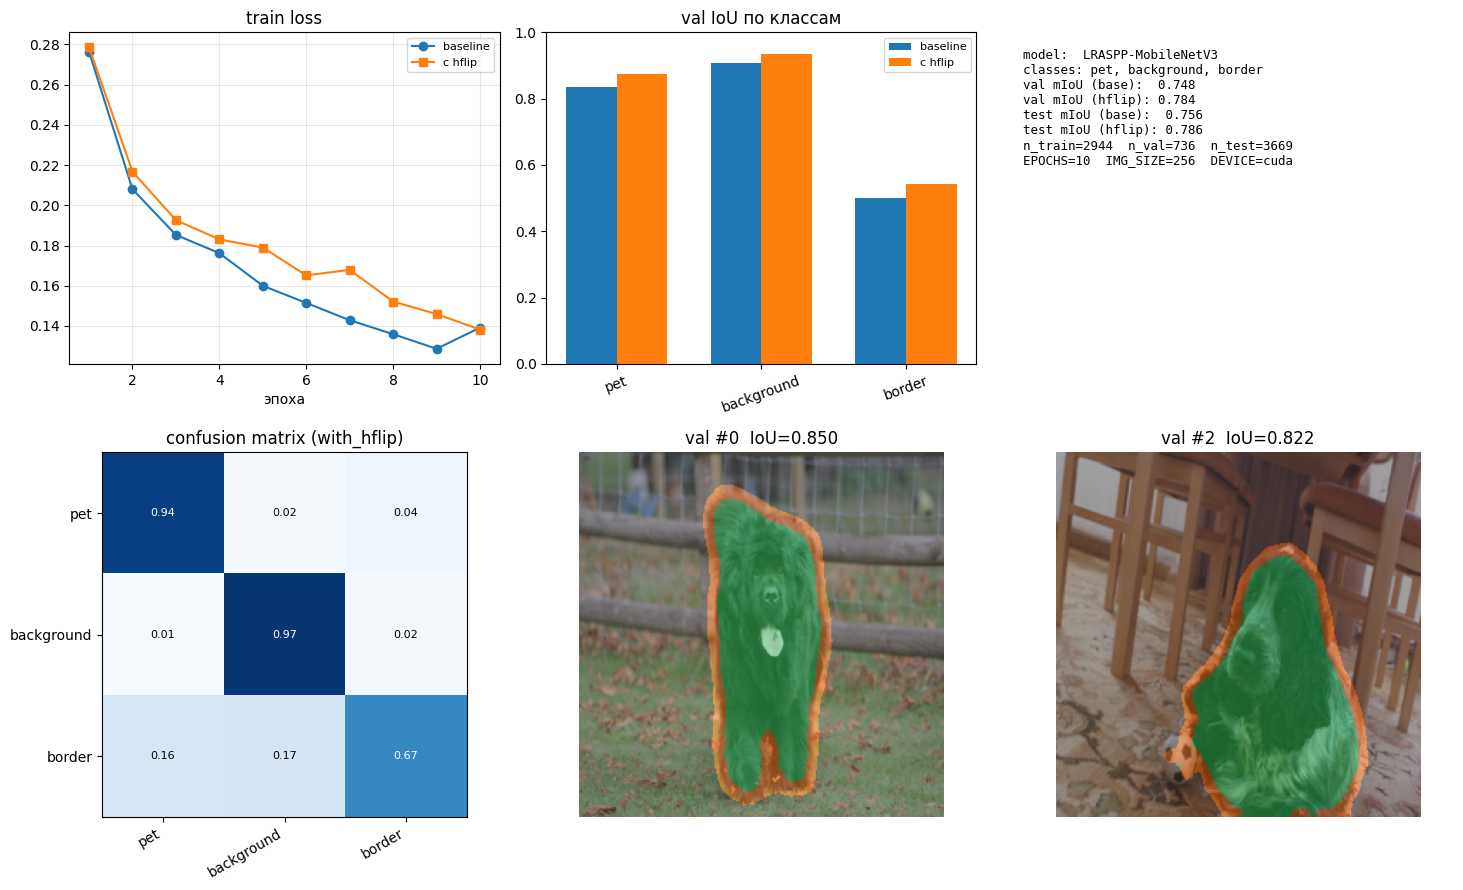

In [35]:
fig = plt.figure(figsize=(15, 9))
gs  = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])

# 1) кривые обучения
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(range(1, len(history) + 1),     history,     marker="o", label="baseline")
ax1.plot(range(1, len(history_aug) + 1), history_aug, marker="s", label="с hflip")
ax1.set_title("train loss"); ax1.set_xlabel("эпоха"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)

# 2) IoU по классам
ax2 = fig.add_subplot(gs[0, 1])
w = 0.35
x_pos = np.arange(len(CLASS_NAMES))
ax2.bar(x_pos - w/2, ious_base, w, label="baseline")
ax2.bar(x_pos + w/2, ious_aug,  w, label="с hflip")
ax2.set_xticks(x_pos); ax2.set_xticklabels(CLASS_NAMES, rotation=20)
ax2.set_ylim(0, 1); ax2.set_title("val IoU по классам"); ax2.legend(fontsize=8)

# 3) числа
ax3 = fig.add_subplot(gs[0, 2]); ax3.axis("off")
txt = (f"model:  LRASPP-MobileNetV3\n"
       f"classes: {', '.join(CLASS_NAMES)}\n"
       f"val mIoU (base):  {val_miou:.3f}\n"
       f"val mIoU (hflip): {val_miou_aug:.3f}\n"
       f"test mIoU (base):  {test_miou_base:.3f}\n"
       f"test mIoU (hflip): {test_miou_aug:.3f}\n"
       f"n_train={len(train_ds)}  n_val={len(val_ds)}  n_test={len(test_ds)}\n"
       f"EPOCHS={EPOCHS}  IMG_SIZE={IMG_SIZE}  DEVICE={DEVICE}")
ax3.text(0, 0.95, txt, va="top", family="monospace", fontsize=9)

# 4) confusion matrix лучшей модели
best_cm  = test_cm_aug if best_model is model_aug else test_cm_base
cm_f     = best_cm.astype(float)
cm_norm  = cm_f / np.maximum(cm_f.sum(1, keepdims=True), 1)
ax4 = fig.add_subplot(gs[1, 0])
im = ax4.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax4.set_xticks(range(3)); ax4.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax4.set_yticks(range(3)); ax4.set_yticklabels(CLASS_NAMES)
ax4.set_title(f"confusion matrix ({best_name})")
for i in range(3):
    for j in range(3):
        ax4.text(j, i, f"{cm_norm[i,j]:.2f}", ha="center", va="center",
                 color="white" if cm_norm[i,j] > 0.5 else "black", fontsize=8)

# 5-6) два примера
with torch.no_grad():
    for k in range(2):
        axp = fig.add_subplot(gs[1, 1 + k])
        idx = val_small_idx[k] if k < len(val_small_idx) else k
        x, y = val_ds[idx]
        with autocast(enabled=AMP_ENABLED):
            pred = best_model(x.unsqueeze(0).to(DEVICE))["out"].argmax(1).squeeze(0).cpu()
        axp.imshow(overlay(denorm(x), pred.numpy()))
        axp.set_title(f"val #{idx}  IoU={mean_iou(pred, y):.3f}")
        axp.axis("off")

plt.tight_layout()
plt.savefig(ARTIFACTS / "summary_dashboard.png", dpi=130)
plt.show()
plt.close()

## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


1. Эффективность аугментации (Ablation Study)
Сравнение базовой модели (baseline) и модели с горизонтальным отражением (hflip) доказало пользу аугментации. Несмотря на то, что на тренировочной выборке loss у модели с hflip оказался чуть выше (из-за усложнения задачи), на независимом тесте она показала значительный прирост: test mIoU вырос с 0.756 до 0.786 (+3%). Это свидетельствует о снижении переобучения и лучшей обобщающей способности модели.

2. Анализ по классам и узкие места
Модель демонстрирует высокое качество на макроуровне:

Фон (background): IoU = 0.93 (почти идеально).

Питомец (pet): IoU = 0.87 (отличный результат).

Граница (border): IoU = 0.55 (главное узкое место).

По матрице ошибок (Confusion Matrix) видно, что модель отлично отделяет питомца от фона (ошибки 1-2%), но «плывет» на границах. Около 33% пикселей контура модель ошибочно относит либо к телу питомца, либо к фону. Это связано с физической сложностью класса border (тонкая линия, шерсть, размытие).

3. Влияние размера объекта
Анализ распределения площади питомцев показал, что модель не имеет «слепоты» к мелким объектам. IoU для маленьких и больших питомцев сопоставим (около 0.82–0.85). Основные ошибки возникают не из-за размера, а из-за сложных поз (например, собака присела) или сложных фонов (трава, вода), где модель склонна «раздувать» объект (False Positive).

4. Диагностика данных
В ходе поиска сложнейшего кейса (худшее изображение idx=698, IoU=0.265) было доказано наличие шума в разметке (Label Noise) датасета. Модель корректно выделила питомца на фото, однако истинная маска (GT) оказалась полностью пустой (true_pet_pixels = 0). Это доказывает, что часть ошибок на валидации обусловлена не дефектами нейросети, а браком в аннотациях, что требует предварительной фильтрации данных (Data Cleaning).